# 04 — Decisão, explicação e teste

Usa o LightGBM escolhido em `03_modelos.ipynb` (salvo em `models/`), treinado só no período de treino.
1. **4.1** — escolher o limiar de decisão pelo custo, na validação.
2. **4.2** — entender o que o modelo usa.
3. **4.3** — avaliar no teste, uma vez só, com tudo já decidido.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import graficos

graficos.aplicar_estilo()

modelo = joblib.load("../models/lightgbm.joblib")
validacao = pd.read_parquet("../data/processed/validacao.parquet")

y_validacao = validacao["is_canceled"].to_numpy()
prob_validacao = modelo.predict_proba(validacao[modelo.feature_names_in_])[:, 1]

## 4.1 Limiar de decisão pelo custo

O modelo dá uma probabilidade, mas o hotel precisa de um sim ou não: contatar ou não esta reserva. O corte (limiar) não deve ser 0,5 por padrão — ele depende de quanto custa errar para cada lado.

**Cenário** (suposição, para ser trocada pelos números reais do hotel):
- A ação é contatar a reserva e oferecer um incentivo para confirmar (por exemplo, upgrade ou desconto). Custa **€30 por reserva contatada** — inclusive nas que não iam cancelar.
- Quando a reserva ia mesmo cancelar, o contato **recupera 25% do valor da reserva** (diária × noites): em parte dos casos o hóspede mantém a reserva ou o quarto é revendido a tempo.

Lucro de um limiar = 25% do valor das reservas contatadas que iam cancelar − €30 × reservas contatadas.

*A base não informa a moeda; como os hotéis são em Portugal, os valores são tratados como euro.*

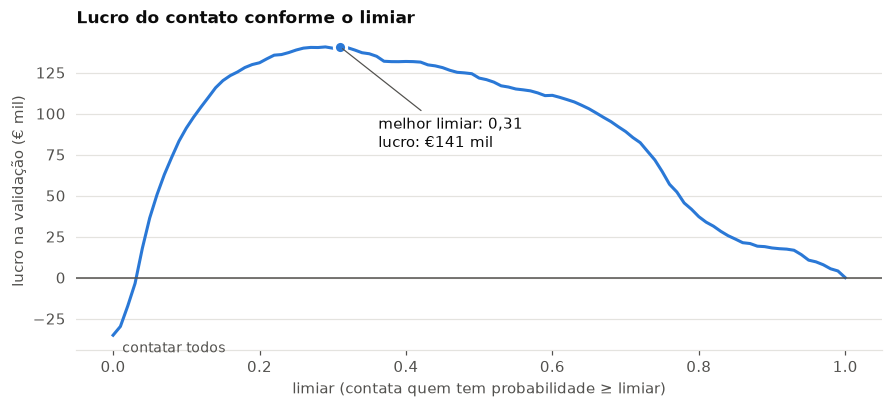

In [2]:
CUSTO_CONTATO = 30  # € por reserva contatada
RECUPERACAO = 0.25  # fração do valor recuperada quando a reserva ia cancelar

valor_reserva = (validacao["adr"] * (validacao["stays_in_weekend_nights"] + validacao["stays_in_week_nights"])).to_numpy()


def lucro(contatar, custo=CUSTO_CONTATO, recuperacao=RECUPERACAO):
    """Lucro de contatar as reservas marcadas em `contatar` (array de True/False)."""
    ganho = (y_validacao[contatar] * recuperacao * valor_reserva[contatar]).sum()
    return ganho - custo * contatar.sum()


limiares = np.round(np.arange(0, 1.0001, 0.01), 2)
curva = pd.Series([lucro(prob_validacao >= t) for t in limiares], index=limiares)
melhor = curva.idxmax()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curva.index, curva / 1000, color=graficos.AZUL, linewidth=2)
ax.axhline(0, color=graficos.TEXTO_SECUNDARIO, linewidth=1)
ax.plot(melhor, curva[melhor] / 1000, "o", color=graficos.AZUL, markersize=8, markeredgecolor="white", markeredgewidth=2)
ax.annotate(f"melhor limiar: {melhor:.2f}\nlucro: €{curva[melhor] / 1000:.0f} mil".replace(".", ","),
            (melhor, curva[melhor] / 1000), xytext=(25, -45), textcoords="offset points", va="top",
            arrowprops=dict(arrowstyle="-", color=graficos.TEXTO_SECUNDARIO, linewidth=0.8))
ax.annotate("contatar todos", (0, curva[0] / 1000), xytext=(6, -4), textcoords="offset points", va="top",
            color=graficos.TEXTO_SECUNDARIO, fontsize=9)
ax.set_xlabel("limiar (contata quem tem probabilidade ≥ limiar)")
ax.set_ylabel("lucro na validação (€ mil)")
ax.set_title("Lucro do contato conforme o limiar")
plt.show()

**Comparando estratégias** — quantas reservas são contatadas, quantas delas iam cancelar de fato, quantos dos cancelamentos são alcançados e o lucro.

In [3]:
estrategias = {
    "não contatar ninguém": np.zeros(len(prob_validacao), dtype=bool),
    "contatar todos": np.ones(len(prob_validacao), dtype=bool),
    "top 10%": prob_validacao >= np.quantile(prob_validacao, 0.90),
    "limiar padrão 0,5": prob_validacao >= 0.5,
    f"limiar escolhido {melhor:.2f}".replace(".", ","): prob_validacao >= melhor,
}

pd.DataFrame({
    nome: {
        "% contatadas": contatar.mean(),
        "das contatadas, iam cancelar": y_validacao[contatar].mean() if contatar.any() else np.nan,
        "dos cancelamentos, alcançados": y_validacao[contatar].sum() / y_validacao.sum(),
        "lucro (€ mil)": lucro(contatar) / 1000,
    }
    for nome, contatar in estrategias.items()
}).T.round(3)

,% contatadas,"das contatadas, iam cancelar","dos cancelamentos, alcançados",lucro (€ mil)
não contatar ninguém,0.000,NaN,0.000,0.000
contatar todos,1.000,0.284,1.000,-35.103
top 10%,0.100,0.741,0.260,85.469
"limiar padrão 0,5",0.186,0.684,0.448,121.650
"limiar escolhido 0,31",0.306,0.588,0.632,140.748


Com o limiar 0,31, o hotel contata 31% das reservas; 59% delas iam cancelar, e o contato alcança 63% de todos os cancelamentos. O lucro é de **€141 mil** nos 4 meses da validação, contra €122 mil com o limiar padrão 0,5, €85 mil contatando só o top 10% e **prejuízo** de €35 mil contatando todo mundo.

A curva é achatada perto do topo: entre ~0,22 e ~0,36 o lucro fica a menos de 5% do máximo, então o valor exato do limiar não é crítico. Como o limiar foi escolhido nesses mesmos dados, o lucro da validação é otimista — o número honesto vem do teste (4.3).

**O limiar muda se o cenário mudar.** Melhor limiar para outros custos de contato e taxas de recuperação:

In [4]:
def melhor_limiar(custo, recuperacao):
    return max(limiares, key=lambda t: lucro(prob_validacao >= t, custo, recuperacao))


pd.DataFrame({
    f"recupera {r:.0%}": {f"contato €{c}": melhor_limiar(c, r) for c in [10, 20, 30, 40]}
    for r in [0.10, 0.25, 0.50]
})

,recupera 10%,recupera 25%,recupera 50%
contato €10,0.22,0.11,0.08
contato €20,0.44,0.18,0.11
contato €30,0.72,0.31,0.15
contato €40,0.81,0.42,0.18


Com contato barato (€10) e boa recuperação, vale contatar quase todo mundo (limiar 0,08); com contato caro (€40) e pouca recuperação, só as reservas de risco altíssimo (0,81). **O modelo dá a nota; o custo do negócio decide o corte.** Daqui em diante fica o cenário base (€30 e 25%) e o limiar 0,31.